# Part 2, Topic 1, Lab A (Explorer): Instruction Power Differences - Edit, Run, Watch

---
NOTE: This lab references some (commercial) training material on [ChipWhisperer.io](https://www.ChipWhisperer.io). You can freely execute and use the lab per the open-source license (including using it in your own courses if you distribute similarly), but you must maintain notice about this source location. Consider joining our training course to enjoy the full experience.

---

**SUMMARY:** *In Lab 2_1A you capture four power traces and compare them by eye. This **Explorer** notebook is the "why" companion: you change the numbers yourself - zoom, smooth, count, measure, predict - and watch the plots change, so you can see exactly what a power trace is telling you.*

**LEARNING OUTCOMES:**

* Read a power trace: what the x-axis (samples and clock cycles) and the y-axis (inverted voltage) mean
* Recognise a loop in a trace and count its iterations - automatically, and by eye
* Measure how many clock cycles one loop iteration takes
* See that the *data* an instruction works on can change how long it takes
* Predict what the trace will look like when you change the loop count, and (with hardware) check your prediction on a real chip

## How this notebook works

Every code cell that you are meant to change starts with the line **`# ✏️ EDIT THESE`**. The recipe is always the same:

1. **Read** the short explanation above the cell.
2. **Change** one of the numbers in the ✏️ block.
3. Press **Shift + Enter** to run the cell and **watch the plot and the printed numbers change**.
4. Change it again. Break it on purpose - you cannot hurt anything. If you get lost, use **Kernel > Restart & Run All**.

| Steps | What you do | Needs hardware? |
|---|---|---|
| 1 - 6 | Explore four real power traces that were recorded earlier on a real target. | **No** |
| 7 | Change the C code on a real ChipWhisperer-Husky + SAM4S target and capture your own trace. | **Yes** (`VERSION = 'HARDWARE'`) |
| 8 | Check your understanding. | No |

Quick keys: **Shift+Enter** run the cell and move on  |  **Ctrl+Enter** run and stay  |  **Esc, then A / B** insert a cell above / below.

## Prerequisites

* ☑ **Lab 0 - SCA101 Setup** passed (the software checks at least).
* ☑ Jupyter basics: you can run a cell. Nothing else is assumed.
* (Optional) **Lab 2_1A (MAIN)** first - this notebook explains what you saw there. You can do it before or after.

## Setup

Run the next two cells and wait for `✔️ Ready!`.

* `VERSION = 'SIMULATED'` - use the recorded traces (default). Steps 1 - 6 work with no hardware at all.
* `VERSION = 'HARDWARE'` - also connect to your ChipWhisperer so Step 7 can build, flash and capture your own code.

In [1]:
# ✏️ EDIT THESE
VERSION = 'SIMULATED'      # 'SIMULATED' = recorded traces only.  'HARDWARE' = also enables Step 7.

# Only used when VERSION = 'HARDWARE' (the settings for the ChipWhisperer-Husky kit with the SAM4S target):
SCOPETYPE = 'OPENADC'
PLATFORM  = 'CWHUSKY'
CRYPTO_TARGET = 'NONE'
SS_VER = 'SS_VER_2_1'

In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

if VERSION == 'HARDWARE':
    %run "Lab 2_1A - Instruction Power Differences (HARDWARE).ipynb"
elif VERSION != 'SIMULATED':
    raise ValueError("VERSION must be 'SIMULATED' or 'HARDWARE'")

plt.rcParams.update({"figure.figsize": (11, 3.4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.titlesize": 11, "axes.labelsize": 10})

TRACE_NAMES = ["0: empty (nothing between the triggers)",
               "1: 20 multiplies, one after another",
               "2: loop that does 20 multiplies",
               "3: loop that does 20 divides"]
traces = [np.load("traces/lab2_1A_trace{}.npy".format(i)) for i in range(4)]
SAMPLES_PER_CYCLE = None          # you will measure this yourself in Step 2


def moving_average(x, width):
    """Smooth a trace: every point becomes the average of `width` neighbouring points."""
    width = int(width)
    if width <= 1:
        return np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(width) / width, mode="same")


def find_pulses(x, smooth_width=21, min_gap=30, tolerance=0.4):
    """Find the repeating humps made by a loop. Returns one sample number per loop iteration.
    1. Smooth the trace.   2. Find the local highs that are at least `min_gap` samples apart.
    3. Keep the first run of highs whose spacing stays within +/- `tolerance` of the previous spacing."""
    sm = moving_average(x, smooth_width)
    h = int(min_gap)
    highs = [i for i in range(h, len(x) - h) if sm[i] == sm[i - h: i + h + 1].max()]
    if not highs:
        return []
    run = [highs[0]]
    for p in highs[1:]:
        gap = p - run[-1]
        if len(run) >= 2:
            prev = run[-1] - run[-2]
            if abs(gap - prev) > tolerance * prev:
                break
        run.append(p)
    return run


def plot_trace(x, start=0, end=None, smooth_width=1, flip=False, pulses=None, cycle_lines=False,
               title="", ax=None, label=None, color=None):
    """Plot samples start..end of trace x. Returns the axes so you can draw more on top."""
    end = len(x) if end is None else end
    if ax is None:
        _, ax = plt.subplots()
    y = moving_average(x, smooth_width)[start:end]
    y = -y if flip else y
    ax.plot(np.arange(start, end), y, lw=0.9, label=label, color=color)
    if cycle_lines and SAMPLES_PER_CYCLE:
        for c in range((start // SAMPLES_PER_CYCLE) * SAMPLES_PER_CYCLE, end + 1, SAMPLES_PER_CYCLE):
            ax.axvline(c, color="tab:red", lw=0.4, alpha=0.35)
    if pulses is not None and len(pulses):
        p = np.array([q for q in pulses if start <= q < end], dtype=int)
        if p.size:
            ym = np.asarray(moving_average(x, smooth_width))[p]
            ax.plot(p, -ym if flip else ym, "v", color="tab:red", ms=7, label="pulse")
    ax.set_xlabel("sample number")
    ax.set_ylabel("power (up = more)" if flip else "ADC value (down = more power)")
    if title:
        ax.set_title(title)
    return ax


print("✔️ Ready!  Loaded", len(traces), "recorded traces of", len(traces[0]), "samples each.",
      "(HARDWARE mode: live capture is also available.)" if VERSION == 'HARDWARE' else "")

✔️ Ready!  Loaded 4 recorded traces of 2000 samples each. 


## Step 1 - Look at a power trace

The ChipWhisperer measures the voltage across a tiny resistor in the target's power supply, once per sample. A **trace** is just a long list of those numbers - here, **2000 of them** per trace.

* **x-axis:** the sample number - time, in tiny steps.
* **y-axis:** the measured value. **Careful:** ChipWhisperer measures a *voltage drop*, so the trace is **upside down** - *larger negative swings mean more power.* The `FLIP` option below turns it the right way up.

The four recorded traces came from the same firmware with different code between the **trigger** signals:

| Trace | What the target was doing inside the trigger window |
|---|---|
| 0 | Nothing (the baseline) |
| 1 | 20 multiplies, one after another |
| 2 | A loop that does the multiply 20 times |
| 3 | A loop that does a divide 20 times |

**Try:** change `TRACE`, then narrow the window to `START, END = 0, 100` so you can see individual samples. Turn `SMOOTH` up to 9 and watch the noise melt away. Set `FLIP = True`.

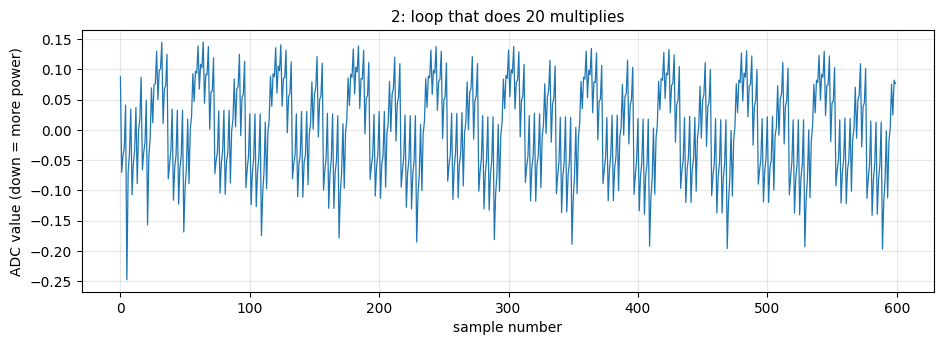

showing samples 0 to 600 - 600 samples out of 2000


In [3]:
# ✏️ EDIT THESE
TRACE      = 2        # which recorded trace: 0, 1, 2 or 3
START, END = 0, 600   # zoom window, in samples (the whole trace is 0 to 2000)
SMOOTH     = 1        # smoothing width: 1 = raw samples, bigger = smoother
FLIP       = False    # True = upside down, so UP means MORE power

plot_trace(traces[TRACE], START, END, SMOOTH, FLIP, title=TRACE_NAMES[TRACE])
plt.show()
print("showing samples", START, "to", END, "-", END - START, "samples out of", len(traces[TRACE]))

## Step 2 - How fast is the clock? (measure it yourself)

A microcontroller does its work in steps timed by a **clock**. The ChipWhisperer takes **several samples per clock cycle**. How many? Don't look it up - measure it.

The trick is **autocorrelation**: compare the trace with a copy of itself slid sideways by `L` samples. If something repeats every `L` samples, the two copies line up well at that `L` and the match score is high. The best score between 2 and 8 samples tells you the clock period.

**Try:** run it. Then change `LAG_MIN, LAG_MAX` to `5, 12` and run again - the winner changes to a *multiple* of the real answer. Why? (A pattern that repeats every 4 samples also repeats every 8.)

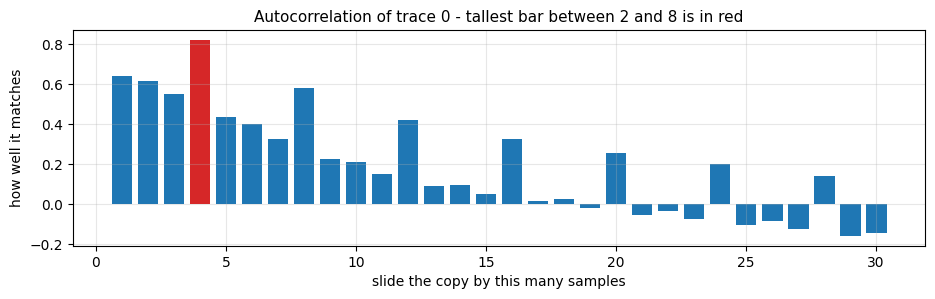

best repeat period: 4 samples  ->  one clock cycle = 4 samples


In [4]:
# ✏️ EDIT THESE
TRACE_FOR_CLOCK = 0      # which trace to analyse (0 to 3)
LAG_MIN, LAG_MAX = 2, 8  # search for the repeat period between these two numbers of samples

x = traces[TRACE_FOR_CLOCK] - traces[TRACE_FOR_CLOCK].mean()
acf = np.correlate(x, x, "full")[len(x) - 1: len(x) + 30]
acf = acf / acf[0]                       # 1.0 at lag 0 (a trace matches itself perfectly)
lags = np.arange(LAG_MIN, LAG_MAX + 1)
best = int(lags[np.argmax(acf[LAG_MIN: LAG_MAX + 1])])

fig, ax = plt.subplots(figsize=(11, 2.8))
ax.bar(range(1, 31), acf[1:31], color=["tab:red" if l == best else "tab:blue" for l in range(1, 31)])
ax.set_xlabel("slide the copy by this many samples"); ax.set_ylabel("how well it matches")
ax.set_title("Autocorrelation of trace {} - tallest bar between {} and {} is in red".format(TRACE_FOR_CLOCK, LAG_MIN, LAG_MAX))
plt.show()

SAMPLES_PER_CYCLE = best   # used by every later step
print("best repeat period: {} samples  ->  one clock cycle = {} samples".format(best, SAMPLES_PER_CYCLE))

**See it in the trace.** The red lines below mark every clock cycle. Notice how the shape repeats from one red line to the next.

**Try:** slide `ZOOM` along the trace (for example `0`, `500`, `1500`) and see whether the cycle lines still line up with the repeating shape.

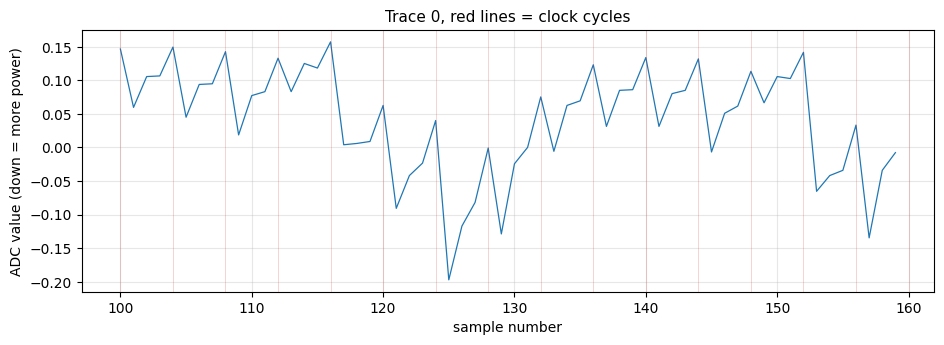

60 samples = 15.0 clock cycles


In [5]:
# ✏️ EDIT THESE
ZOOM = 100            # first sample to show
WIDTH = 60            # how many samples to show

plot_trace(traces[0], ZOOM, ZOOM + WIDTH, cycle_lines=True, title="Trace 0, red lines = clock cycles")
plt.show()
print("{} samples = {} clock cycles".format(WIDTH, WIDTH / SAMPLES_PER_CYCLE))

## Step 3 - Compare two traces

Trace 0 is the baseline (nothing happening). Does adding 20 multiplies change the trace? Plot any two traces on top of each other and **slide one sideways** to see whether they line up.

**Try:**

* `A_TRACE, B_TRACE = 0, 1` - can you *see* the 20 multiplies? (Be honest: how much changed?)
* `A_TRACE, B_TRACE = 0, 2` - now compare against the loop. Much easier to spot!
* Use `SHIFT_B` to slide the orange trace left or right. Does it ever line up with the blue one?

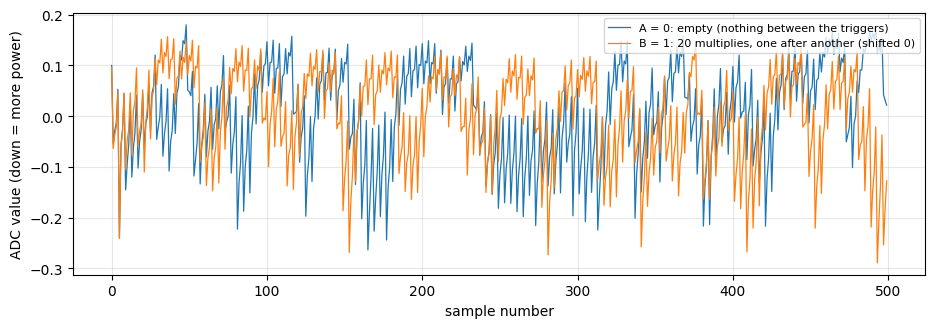

average difference between the two in this window: 0.0943
for scale: the wiggles in trace A are typically 0.0942 in size
(if the average difference is about as big as the wiggles themselves, the two traces do not line up at all)


In [6]:
# ✏️ EDIT THESE
A_TRACE, B_TRACE = 0, 1     # which two traces to compare (0 to 3)
SHIFT_B = 0                 # slide trace B to the right (+) or left (-) by this many samples
START, END = 0, 500         # zoom window

a, b = traces[A_TRACE], np.roll(traces[B_TRACE], SHIFT_B)
ax = plot_trace(a, START, END, label="A = " + TRACE_NAMES[A_TRACE])
plot_trace(b, START, END, ax=ax, label="B = " + TRACE_NAMES[B_TRACE] + " (shifted {})".format(SHIFT_B), color="tab:orange")
ax.legend(loc="upper right", fontsize=8)
plt.show()
diff = np.abs(a[START:END] - b[START:END])
print("average difference between the two in this window: {:.4f}".format(diff.mean()))
print("for scale: the wiggles in trace A are typically {:.4f} in size".format(a[START:END].std()))
print("(if the average difference is about as big as the wiggles themselves, the two traces do not line up at all)")

## Step 4 - Find the loop

A loop runs the same few instructions again and again, so its trace is **the same shape repeated** - one **pulse** per trip round the loop. `find_pulses()` finds them: smooth the trace, find the repeating highs, and stop when the pattern stops repeating.

Three knobs control it:

| Knob | Meaning |
|---|---|
| `SMOOTH_WIDTH` | How hard to smooth before looking for highs. |
| `MIN_GAP` | Highs closer together than this many samples count as the same pulse. |
| `TOLERANCE` | How much the spacing may change from one pulse to the next (0.4 = 40%). |

**Try:**

1. Run it as it is. How many pulses in each loop? What is the spacing between pulses, in samples and in clock cycles?
2. Set `SMOOTH_WIDTH = 3`. What happens to the count? *(Too little smoothing: noise makes fake highs.)*
3. Set `SMOOTH_WIDTH = 101`. Now what? *(Too much smoothing: the pulses blur into each other.)*
4. Find the range of `SMOOTH_WIDTH` that gives the right answer for **both** traces.
5. Add `0` and `1` to `LOOP_TRACES`. These traces contain no loop - what does the finder say?

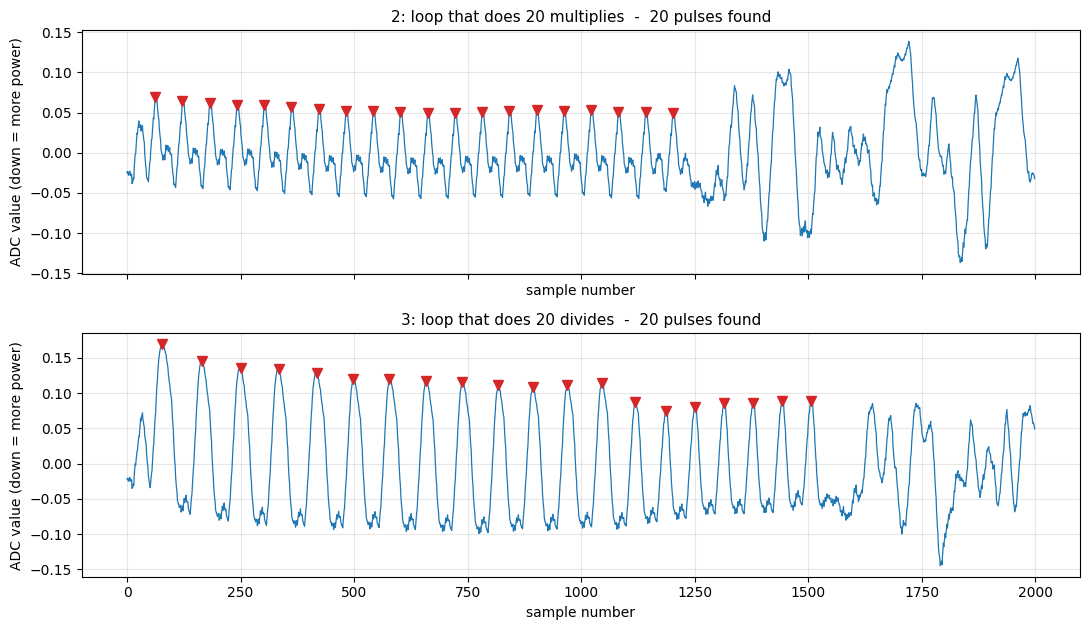

trace 2: 20 pulses
   spacing in samples: [60, 60, 60, 60, 60, 60, 60, 60, 60, 60, 60, 60, 60, 60, 60, 60, 60, 60, 60]
   spacing in cycles : [15.0, 15.0, 15.0, 15.0, 15.0, 15.0, 15.0, 15.0, 15.0, 15.0, 15.0, 15.0, 15.0, 15.0, 15.0, 15.0, 15.0, 15.0, 15.0]
trace 3: 20 pulses
   spacing in samples: [88, 84, 84, 84, 80, 80, 80, 80, 80, 76, 76, 76, 72, 68, 64, 64, 64, 64, 64]
   spacing in cycles : [22.0, 21.0, 21.0, 21.0, 20.0, 20.0, 20.0, 20.0, 20.0, 19.0, 19.0, 19.0, 18.0, 17.0, 16.0, 16.0, 16.0, 16.0, 16.0]


In [7]:
# ✏️ EDIT THESE
SMOOTH_WIDTH = 21        # smoothing width used before looking for highs
MIN_GAP      = 30        # smallest allowed spacing between pulses, in samples
TOLERANCE    = 0.4       # how much the spacing may change from pulse to pulse
LOOP_TRACES  = [2, 3]    # which traces to analyse

fig, axes = plt.subplots(len(LOOP_TRACES), 1, figsize=(11, 3.2 * len(LOOP_TRACES)), sharex=True, squeeze=False)
for ax, t in zip(axes[:, 0], LOOP_TRACES):
    found = find_pulses(traces[t], SMOOTH_WIDTH, MIN_GAP, TOLERANCE)
    plot_trace(traces[t], 0, 2000, SMOOTH_WIDTH, pulses=found, ax=ax, title=TRACE_NAMES[t] + "  -  {} pulses found".format(len(found)))
plt.tight_layout(); plt.show()

for t in LOOP_TRACES:
    found = find_pulses(traces[t], SMOOTH_WIDTH, MIN_GAP, TOLERANCE)
    gaps = np.diff(found)
    print("trace {}: {} pulses".format(t, len(found)))
    if len(gaps):
        print("   spacing in samples:", gaps.tolist())
        print("   spacing in cycles :", (gaps / SAMPLES_PER_CYCLE).tolist())

**What do you notice about the two loops?**

* The **multiply** loop: every pulse is the same distance from the last. Same work every time round, same time every time.
* The **divide** loop: the pulses start further apart and **get closer together**. The loop is doing the *same instructions* every time, yet each trip gets *faster*. Why? That is Step 5.

> **Aside - what is actually in the loop?** The firmware is C, but the chip runs machine code. The compiler turned `A *= 2` into a **shift** (`lsls`), not a multiply - that is a free optimisation, because multiplying by 2 is just shifting. One trip round the loop is roughly ten instructions, most of them loading and storing the two `volatile` variables from memory:
>
> * `str` / `ldr` of `i`, then `cmp`, `ble` - loop control: store `i`, load `i`, compare with 19, branch
> * `ldr` of `A` - load `A` from memory
> * `lsls` (or `sdiv` in the divide loop) - **the operation under test**
> * `str` of `A` - store `A` back to memory
> * `ldr` of `i`, `adds`, `b` - load `i`, add 1, jump back
>
> (Listing from `arm-none-eabi-gcc` 10.3.1; other compiler versions order things slightly differently. After a hardware build you can read your own in `firmware/mcu/simpleserial-base-lab2/simpleserial-base-CWHUSKY.lss`.)

## Step 5 - Why does the divide loop speed up?

Division is hard for a processor. The ARM documentation says the divide instruction takes **between 2 and 12 cycles depending on the numbers it is dividing**. In the divide loop the firmware did `A /= 3` twenty times, starting from `A = 0x7FFFFFFF`. After every divide `A` is a third of what it was - so **the number gets smaller each trip**.

The table below puts the two side by side: the size of `A` (how many binary digits, or *bits*, it needs) and how long the trip took.

**Try:**

* Run it and look at the correlation `r` printed at the bottom. Near **+1** means "the two move together". What does that tell you?
* Edit `A_START` and `DIVISOR` and watch the `A` and `bits` columns change. (The *measured* column cannot change - the recorded trace used `0x7FFFFFFF` and `3`. You will test a different start value on real hardware in Step 7.)

trip |  A (before the divide) | bits in A | measured cycles for this trip
   0 |             0x7fffffff |        31 |   22.0
   1 |             0x2aaaaaaa |        30 |   21.0
   2 |              0xe38e38e |        28 |   21.0
   3 |              0x4bda12f |        27 |   21.0
   4 |              0x1948b0f |        25 |   20.0
   5 |               0x86d905 |        24 |   20.0
   6 |               0x2cf301 |        22 |   20.0
   7 |                0xefbab |        20 |   20.0
   8 |                0x4fe8e |        19 |   20.0
   9 |                0x1aa2f |        17 |   19.0
  10 |                 0x8e0f |        16 |   19.0
  11 |                 0x2f5a |        14 |   19.0
  12 |                  0xfc8 |        12 |   18.0
  13 |                  0x542 |        11 |   17.0
  14 |                  0x1c0 |         9 |   16.0
  15 |                   0x95 |         8 |   16.0
  16 |                   0x31 |         6 |   16.0
  17 |                   0x10 |         5 |   16.0
  18 |  

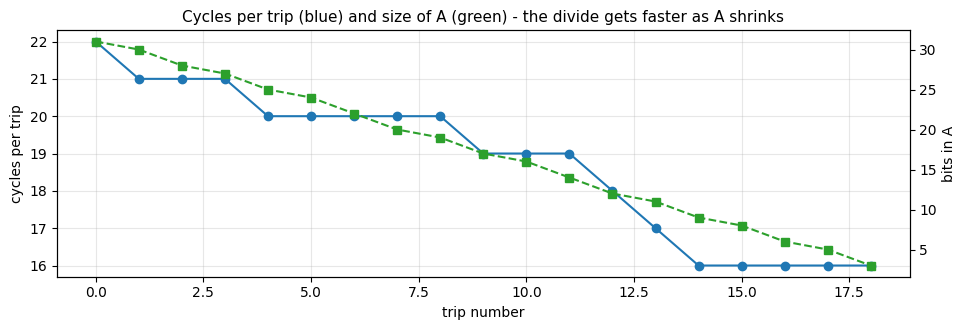

correlation between 'bits in A' and 'cycles per trip': r = +0.97


In [8]:
# ✏️ EDIT THESE
A_START = 0x7FFFFFFF     # the value the recorded firmware started with
DIVISOR = 3              # the number it divided by

found = find_pulses(traces[3], 21, 30, 0.4)
measured = np.diff(found) / SAMPLES_PER_CYCLE      # cycles for each trip round the loop

A, rows = A_START, []
for k in range(len(measured)):
    rows.append((k, A, A.bit_length(), measured[k]))
    A //= DIVISOR

print("trip |  A (before the divide) | bits in A | measured cycles for this trip")
for k, a_val, bits, cyc in rows:
    print("{:4d} | {:>22} | {:9d} | {:6.1f}".format(k, hex(a_val), bits, cyc))

bits = np.array([r[2] for r in rows]); cyc = np.array([r[3] for r in rows])
r = np.corrcoef(bits, cyc)[0, 1]
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot([r_[0] for r_ in rows], cyc, "o-", label="measured cycles per trip")
ax.set_xlabel("trip number"); ax.set_ylabel("cycles per trip")
ax2 = ax.twinx(); ax2.plot([r_[0] for r_ in rows], bits, "s--", color="tab:green", label="bits in A"); ax2.set_ylabel("bits in A")
ax.set_title("Cycles per trip (blue) and size of A (green) - the divide gets faster as A shrinks"); ax2.grid(False)
plt.show()
print("correlation between 'bits in A' and 'cycles per trip': r = {:+.2f}".format(r))

## Step 6 - What if the loop ran 5 times? Or 50?

On real hardware you would have to edit the C code, rebuild and reflash to answer that. Here is a shortcut: take **the real multiply loop**, average its 18 middle trips into one clean **template trip**, and **stack copies of it** to make a trace for *any* loop count. Then add noise like the real chip.

> ⚠️ **This is a model built from real data, not a new measurement.** Real hardware has details this does not. Step 7 lets you check the prediction for real.

**Try:**

1. Run it with `LOOP_COUNT = 20` and compare the top (model) with the bottom (real recording). Close?
2. Set `LOOP_COUNT = 5`, then `50`. Check the printed prediction: *trips × samples per trip = total samples*. Does the pulse finder in the plot title agree with your count?
3. Turn `NOISE` up: `0`, `0.02`, `0.1`, `0.2`. (The real chip's own noise is only about `0.004` - this recording is very clean.) At what level does the pulse finder start getting the count wrong? What would you change in Step 4 to rescue it? *(Try a bigger `SMOOTH_WIDTH`.)*
4. Why can we stack copies of the multiply loop's trip - but *not* of the divide loop's? *(Hint: Step 5.)*

In [9]:
# --- build the template trip from the real multiply loop (trace 2). Nothing to edit here. ---
real_pulses = find_pulses(traces[2], 21, 30, 0.4)
PERIOD = int(np.median(np.diff(real_pulses)))                 # samples per trip (measured, not assumed)
half = PERIOD // 2
trips = np.array([traces[2][p - half: p + half] for p in real_pulses[1:-1]])
template = trips.mean(axis=0)
real_noise = (trips - template).std()
LEAD_IN = traces[2][: real_pulses[0] - half]                                      # real samples before the first trip
LEAD_OUT = traces[2][real_pulses[-1] + half: real_pulses[-1] + half + 40]         # real samples just after the loop
print("template trip: {} samples = {} cycles, averaged from {} real trips".format(
    PERIOD, PERIOD / SAMPLES_PER_CYCLE, len(trips)))
print("trip-to-trip variation in the real recording (its noise): {:.4f}".format(real_noise))


def build_loop_trace(n, noise=0.0, seed=1):
    rng = np.random.default_rng(seed)
    loop = np.tile(template, n) + rng.normal(0, noise, size=n * PERIOD)
    return np.concatenate([LEAD_IN, loop, LEAD_OUT])


def draw_model(n, noise=0.0, seed=1):
    model = build_loop_trace(n, noise, seed)
    fig, axes = plt.subplots(2, 1, figsize=(11, 5.4), sharex=True)
    found = find_pulses(model, 21, 30, 0.4)
    plot_trace(model, 0, len(model), 21, pulses=found, ax=axes[0],
               title="MODEL: {} stacked trips - pulse finder counts {}".format(n, len(found)))
    for k in range(n + 1):
        axes[0].axvline(len(LEAD_IN) + k * PERIOD, color="grey", lw=0.5, alpha=0.5)
    end = min(len(traces[2]), real_pulses[-1] + half)
    plot_trace(traces[2], 0, end, 21, pulses=real_pulses, ax=axes[1], title="REAL recording (trace 2): 20 trips")
    axes[1].set_xlim(0, max(len(model), end))
    plt.tight_layout(); plt.show()
    print("prediction: {} trips x {} samples = {} samples = {:.0f} clock cycles".format(
        n, PERIOD, n * PERIOD, n * PERIOD / SAMPLES_PER_CYCLE))

template trip: 60 samples = 15.0 cycles, averaged from 18 real trips
trip-to-trip variation in the real recording (its noise): 0.0045


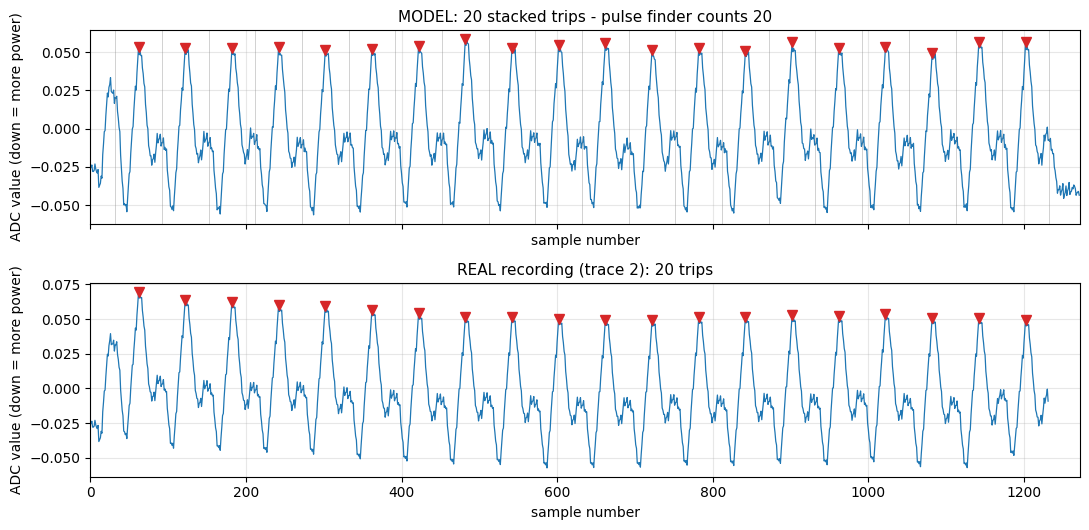

prediction: 20 trips x 60 samples = 1200 samples = 300 clock cycles


In [10]:
# ✏️ EDIT THESE
LOOP_COUNT = 20      # how many trips round the loop
NOISE      = 0.01    # extra noise added to the model: 0 = perfectly clean, 0.1 = quite noisy, 0.3 = awful
SEED       = 1       # change this for a different random noise pattern

draw_model(LOOP_COUNT, NOISE, SEED)

**Slider version.** The same model with sliders - drag them and the plot updates as you go. (If the sliders do not appear, you can keep using the cell above; it does the same thing.)

In [ ]:
try:
    import ipywidgets as widgets
    from IPython.display import display
    s_n = widgets.IntSlider(value=20, min=1, max=60, description="trips", continuous_update=False)
    s_noise = widgets.FloatSlider(value=0.01, min=0.0, max=0.3, step=0.01, description="noise", continuous_update=False)
    out = widgets.interactive_output(lambda n, noise: draw_model(n, noise, 1), {"n": s_n, "noise": s_noise})
    display(widgets.VBox([s_n, s_noise, out]))
except ImportError:
    print("ipywidgets is not installed - use the cell above instead.")

## Step 7 - Your turn on the real chip (hardware only)

Now test your predictions on the real target. This step **edits the C code that runs between the triggers**, rebuilds the firmware, flashes the chip and captures a fresh trace - then runs the same `find_pulses()` on it.

Needs: the ChipWhisperer-Husky kit connected, and `VERSION = 'HARDWARE'` in the Setup cell (then **Kernel > Restart & Run All** up to here). Each run takes about 10 - 20 seconds because it rebuilds and reflashes.

**Experiments - predict first, then run:**

| Change | What do you predict? |
|---|---|
| `MY_COUNT = 10`, then `40` | How many pulses? How long is the loop in total? |
| `MY_OPERATION = "A += 2;"`, then `"A ^= 0x55;"`, then `"A *= 3;"` | Is the trip still 15 cycles? Can you tell an add from an XOR *by timing*? |
| `MY_OPERATION = "A /= 3;"` with `MY_A_START = "0x7FFFFFFF"` | Do the trips get shorter, like Step 4? |
| Same divide, but `MY_A_START = "0x100"` | Now `A` is small from the start. Do the trips still change length? |

In [12]:
# ✏️ EDIT THESE
MY_OPERATION = "A *= 2;"      # the C statement inside the loop. Try "A += 2;"  "A ^= 0x55;"  "A *= 3;"  "A /= 3;"
MY_COUNT     = 20             # how many trips round the loop
MY_A_START   = "0x2BAA"       # starting value of A (for a divide try "0x7FFFFFFF" or "0x100")

if VERSION != 'HARDWARE':
    print("Step 7 needs a ChipWhisperer. Set VERSION = 'HARDWARE' in the Setup cell, then Restart & Run All.")
else:
    my_code = ("volatile long int A = {};\n"
               "volatile int i;\n"
               "for (i = 0; i < {}; i++) {{\n"
               "    {}\n"
               "}}").format(MY_A_START, MY_COUNT, MY_OPERATION)
    print("C code between the triggers:\n" + my_code + "\n")
    set_user_code(my_code, keep_serial_echo=True)
    build_and_flash()
    my_wave = capture_trace(0)
    my_pulses = find_pulses(my_wave, 21, 30, 0.4)
    plot_trace(my_wave, 0, len(my_wave), 21, pulses=my_pulses,
               title="YOUR capture: {} - {} pulses found (you asked for {})".format(MY_OPERATION, len(my_pulses), MY_COUNT))
    plt.show()
    gaps = np.diff(my_pulses) / SAMPLES_PER_CYCLE
    print("pulses found:", len(my_pulses), "| asked for:", MY_COUNT)
    print("cycles per trip:", gaps.tolist())

Step 7 needs a ChipWhisperer. Set VERSION = 'HARDWARE' in the Setup cell, then Restart & Run All.


## Step 8 - Check your understanding

Try each question yourself first - the answers are in the next cell.

1. How many **samples** make up one clock cycle? How did you find out?
2. How many pulses did the multiply loop make, and how many cycles was each trip? And the divide loop?
3. The divide loop's pulses move closer together. Why?
4. Why is a loop of 20 easier to spot than 20 instructions written out one after another?
5. If the multiply loop ran **10** times instead of 20, what would you expect to see? What about **40**?
6. We wrote `A *= 2;` - is the chip actually using a multiplier? How would you find out?

### Answers

1. **4 samples per cycle.** The autocorrelation of the trace has its tallest bar at 4 samples (Step 2): the shape repeats every 4 samples, and that is the clock.
2. **20 pulses** in each loop. The multiply loop takes **60 samples = 15 cycles** per trip, every trip. The divide loop starts at about 88 samples (22 cycles) per trip and shrinks to about 64 samples (16 cycles).
3. The divide hardware finishes sooner when the numbers are smaller. `A` is divided by 3 on every trip, so it needs fewer and fewer bits (Step 5) and each trip takes fewer cycles. **The data changes the timing.** This is the key idea behind many side-channel attacks.
4. A loop repeats the same shape many times, so the repetition stands out against the noise. 20 separate single-cycle instructions are a short burst of near-identical activity that blends into everything around it. (Looping is also *much* more work per trip: the loop control adds about ten instructions around the one you care about.)
5. **10 pulses** and a loop about **half as long** (about 600 samples); **40 pulses** and about **2400 samples** - - if your capture window is shorter than that you only see the first part of it (the recorded traces are 2000 samples, which fits about 33 trips). Step 6's model shows this; Step 7 lets you check it on hardware.
6. **No.** The compiler replaced `* 2` with a *shift* (`lsls`) because that is cheaper - the same result with no multiplier involved. You find this out by reading the compiled code in the `.lss` file after a hardware build (or the listing in Step 4). Never assume the machine does what the C source looks like it does.

## Conclusions & Next Steps

You have now measured the clock, found a loop, counted its trips, timed each trip, and discovered that the **data** an instruction works on can change **how long it takes** - all straight from the power trace. In **Lab 2_1B** you will use the same idea to break a password check: the chip works a little longer for each correct character, and that difference shows up in the trace.

Things to try next: does `A += 2` look different from `A ^= 0x55`? (Step 7 on hardware.) What does the trace look like if you remove the `volatile` keyword? (Edit `MY_OPERATION`'s surrounding code in the HARDWARE notebook.)

---
<small>NO-FUN DISCLAIMER: This material is Copyright (C) NewAE Technology Inc., 2015-2020. ChipWhisperer is a trademark of NewAE Technology Inc., claimed in all jurisdictions, and registered in at least the United States of America, European Union, and Peoples Republic of China.

Tutorials derived from our open-source work must be released under the associated open-source license, and notice of the source must be *clearly displayed*. Only original copyright holders may license or authorize other distribution - while NewAE Technology Inc. holds the copyright for many tutorials, the github repository includes community contributions which we cannot license under special terms and **must** be maintained as an open-source release. Please contact us for special permissions (where possible).

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY, FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM, OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE SOFTWARE.</small>